# Notebook 02: votação de features

Três modelos de natureza diferente "votam" nas features mais importantes. Uma feature é eleita quando aparece no top 20 de pelo menos 2 dos 3 métodos. A ideia é a mesma de um comitê: cada método tem seus vieses, e o consenso entre eles é mais confiável do que a opinião de um só.

| | Arquivos |
|---|---|
| **Lê** | `config/config.yaml`, `artifacts/ciclo_atual.json`, `data/processed/treino_<data_version>.csv` |
| **Grava** | `artifacts/features_eleitas.json`, `reports/figuras/<cycle_id>_02_*.csv` e `.png`, um run no MLflow (`mlflow.db` e `mlartifacts/`) |

**Sobre vazamento de dados.** A votação usa somente o treino do ciclo. O teste fixo não é lido. Além disso, a votação foi implementada como um transformador do scikit-learn (`SeletorPorVotacao`). No notebook 03 ele fica **dentro do `Pipeline`**, então na validação cruzada a votação é refeita em cada fold usando só a parte de treino daquele fold. Se escolhêssemos as features uma vez com todo o treino e depois validássemos com essa lista, os dados de validação já teriam influenciado a escolha (viés de seleção) e o F1 da validação sairia otimista.

## 0. Preparação do ambiente

Esta célula faz o mesmo notebook rodar sem alterações no **Google Colab**, no **GitHub Actions** e **localmente**:

* **No Colab** (`'google.colab' in sys.modules`): clona o repositório definido em `REPO_URL` dentro de `/content`, entra na pasta e instala o `requirements.txt`. Se o repositório já estiver clonado, só atualiza com `git pull`. Se a instalação trocar a versão de uma biblioteca que o Colab já tinha carregado, a sessão é reiniciada automaticamente: basta executar esta célula de novo.
* **Fora do Colab**: procura a raiz do repositório (a pasta que contém `config/config.yaml`) subindo a partir da pasta atual e muda o diretório de trabalho para ela.

Nos dois casos a raiz entra no `sys.path`, o que permite `from src... import ...`. Todos os caminhos usados depois são relativos à raiz.

**`REPO_URL` já aponta para o repositório do projeto (`https://github.com/eduardaramalho/n3-analise-preditiva.git`). Só altere se o repositório mudar de endereço.**

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/eduardaramalho/n3-analise-preditiva.git"  # repositório do projeto
REPO_BRANCH = "main"

NA_COLAB = "google.colab" in sys.modules

if NA_COLAB:
    pasta_repo = Path("/content") / Path(REPO_URL).stem
    if not (pasta_repo / ".git").exists():
        subprocess.run(["git", "clone", "-b", REPO_BRANCH, REPO_URL, str(pasta_repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(pasta_repo), "pull", "--ff-only"], check=False)
    os.chdir(pasta_repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Se o pip trocou a versão de uma biblioteca já carregada, a sessão precisa reiniciar
    from importlib.metadata import version
    trocadas = [m for m, dist in {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
                                  "matplotlib": "matplotlib"}.items()
                if m in sys.modules and getattr(sys.modules[m], "__version__", version(dist)) != version(dist)]
    if trocadas:
        print(f"Versões atualizadas ({', '.join(trocadas)}). Reiniciando a sessão: execute esta célula de novo.")
        os.kill(os.getpid(), 9)
else:
    raiz = Path.cwd().resolve()
    while not (raiz / "config" / "config.yaml").exists():
        if raiz.parent == raiz:
            raise FileNotFoundError("Raiz do repositório não encontrada (config/config.yaml).")
        raiz = raiz.parent
    os.chdir(raiz)

RAIZ = Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print("Ambiente:", "Google Colab" if NA_COLAB else "local / GitHub Actions")
print("Raiz do repositório:", RAIZ)

Ambiente: local / GitHub Actions
Raiz do repositório: /home/user/n3-analise-preditiva


## 1. Configuração e dados do ciclo

O notebook lê o "crachá" do ciclo (`artifacts/ciclo_atual.json`) gravado pelo notebook 01 e carrega exatamente o treino daquele ciclo. Por segurança, o hash do arquivo é recalculado e comparado com o `data_version`: se alguém tiver alterado o treino entre os notebooks, a execução para.

As features são as 57 colunas originais. `id_email` (identificador) e `lote_origem` (rastreabilidade) não entram no modelo.

In [2]:
import json
from datetime import datetime, timezone

import mlflow
import pandas as pd
from IPython.display import display

from src.utils import carregar_config, caminho, fixar_seed, salvar_json
from src import ingestao, features as F, graficos
from src.preprocessamento import colunas_features
from src.rastreamento import configurar_mlflow

cfg = carregar_config()
SEED = cfg["projeto"]["seed"]
fixar_seed(SEED)
graficos.aplicar_estilo()

ciclo = ingestao.carregar_ciclo(cfg)
CYCLE_ID, DATA_VERSION = ciclo["cycle_id"], ciclo["data_version"]
ALVO, COL_ID = cfg["dados"]["alvo"], cfg["dados"]["coluna_id"]

treino = pd.read_csv(caminho(ciclo["arquivo_treino"]))
hash_atual = ingestao.hash_treino(treino, COL_ID)
if not DATA_VERSION.endswith(f"_h{hash_atual}"):
    raise ValueError(f"O treino não confere com o data_version do ciclo ({DATA_VERSION} x {hash_atual})")

FEATURES = colunas_features(treino, cfg)
X, y = treino[FEATURES], treino[ALVO]
print(f"Ciclo {CYCLE_ID} | {DATA_VERSION}")
print(f"Treino: {X.shape[0]} e-mails x {X.shape[1]} features | spam = {y.mean():.1%}")

Ciclo 20261122T202358Z | lotes-01+02_h0ce6906487cc
Treino: 3363 e-mails x 57 features | spam = 39.9%


## 2. Os três métodos votantes e seus parâmetros

| Método | Como mede a importância | Parâmetros (config.yaml) | Por quê |
|---|---|---|---|
| **RandomForestClassifier** | `feature_importances_`: quanto cada feature reduz a impureza (Gini) nas divisões das árvores, em média | `n_estimators=300`, `max_depth=None`, `n_jobs=-1` | 300 árvores deixam a importância estável. Sem limite de profundidade, cada árvore usa as features à vontade. Captura relações não lineares e interações. Não precisa de escalonamento. |
| **LinearSVC** | valor absoluto de `coef_`: peso da feature na fronteira de separação linear | `C=1.0`, `max_iter=10000`, `dual="auto"` | `C=1` é a regularização padrão. `max_iter` alto garante convergência. `dual="auto"` escolhe a formulação mais eficiente. |
| **LogisticRegression** | valor absoluto de `coef_`: efeito da feature no log da chance de ser spam | `C=1.0`, `solver="lbfgs"`, `max_iter=5000` | Regularização L2 padrão. `lbfgs` é o solver padrão e estável para problemas binários. |

* **StandardScaler nos lineares:** os coeficientes só são comparáveis entre si se as features estiverem na mesma escala. Sem padronizar, `capital_run_length_total` (vai até 15.841) teria coeficiente minúsculo só por causa da escala. O scaler fica **dentro do Pipeline** de cada votante, ajustado só nos dados de treino.
* **Valor absoluto:** um coeficiente muito negativo (ex.: `word_freq_george`, indicador de e-mail legítimo) é tão informativo quanto um muito positivo. O que importa para a votação é a força, não o sinal.
* **seed 42** em todos os modelos que têm aleatoriedade.

In [3]:
v = cfg["votacao"]
TOP_K, VOTOS_MIN, MIN_FEATURES = v["top_k"], v["votos_minimos"], v["minimo_features"]
pd.DataFrame([{"metodo": m, **(p or {})} for m, p in v["modelos"].items()]).set_index("metodo")

,n_estimators,max_depth,n_jobs,C,max_iter,dual,solver
metodo,,,,,,,
RandomForestClassifier,300.0,NaN,-1.0,NaN,NaN,NaN,NaN
LinearSVC,NaN,NaN,NaN,1.0,10000.0,auto,NaN
LogisticRegression,NaN,NaN,NaN,1.0,5000.0,NaN,lbfgs


## 3. Rankings completos dos três métodos

Cada método é ajustado no treino completo do ciclo e ordena as 57 features da mais para a menos importante (posição 1 = mais importante). A tabela abaixo reúne os três rankings e é salva em CSV.

In [4]:
seletor = F.criar_seletor(cfg).fit(X, y)
tabela_votos = seletor.tabela_votos_
ELEITAS = seletor.features_eleitas_

rankings = tabela_votos[["feature", "posicao_rf", "importancia_rf", "posicao_svc", "importancia_svc",
                         "posicao_lr", "importancia_lr"]].sort_values("posicao_rf")
graficos.salvar_tabela(rankings, cfg, CYCLE_ID, "02_rankings_completos")
for metodo, r in seletor.rankings_.items():
    graficos.salvar_tabela(r, cfg, CYCLE_ID, f"02_ranking_{F.SIGLAS[metodo]}")
rankings.round(4)

,feature,posicao_rf,importancia_rf,posicao_svc,importancia_svc,posicao_lr,importancia_lr
21,char_freq_!,1,0.1174,29,0.0963,26,0.3400
2,char_freq_$,2,0.0962,10,0.3634,7,1.2471
4,word_freq_remove,3,0.0793,14,0.2851,8,1.0651
6,word_freq_free,4,0.0692,12,0.2902,13,0.9528
24,capital_run_length_average,5,0.0628,34,0.0779,33,0.2050
22,word_freq_your,6,0.0535,23,0.1248,29,0.3066
3,capital_run_length_longest,7,0.0509,7,0.4649,9,1.0499
0,word_freq_hp,8,0.0493,4,0.7168,2,2.5073
20,capital_run_length_total,9,0.0484,21,0.1448,24,0.3813
28,word_freq_money,10,0.0301,44,0.0353,45,0.0968


## 4. Top 20 de cada método

Os gráficos mostram as 20 features mais importantes de cada método. Cada painel tem a sua própria escala, porque as medidas não são comparáveis entre métodos (impureza na Random Forest, coeficiente padronizado nos lineares). Em azul, as features que acabaram eleitas.

Repare que a Random Forest valoriza features de "volume" (`char_freq_!`, `char_freq_$`, `capital_run_length_*`), enquanto os modelos lineares dão muito peso a palavras raras e muito específicas (`word_freq_george`, `word_freq_cs`, `word_freq_lab`). É por isso que a votação é útil: ela combina visões diferentes.

PosixPath('/home/user/n3-analise-preditiva/reports/figuras/20261122T202358Z_02_importancias_top20.png')

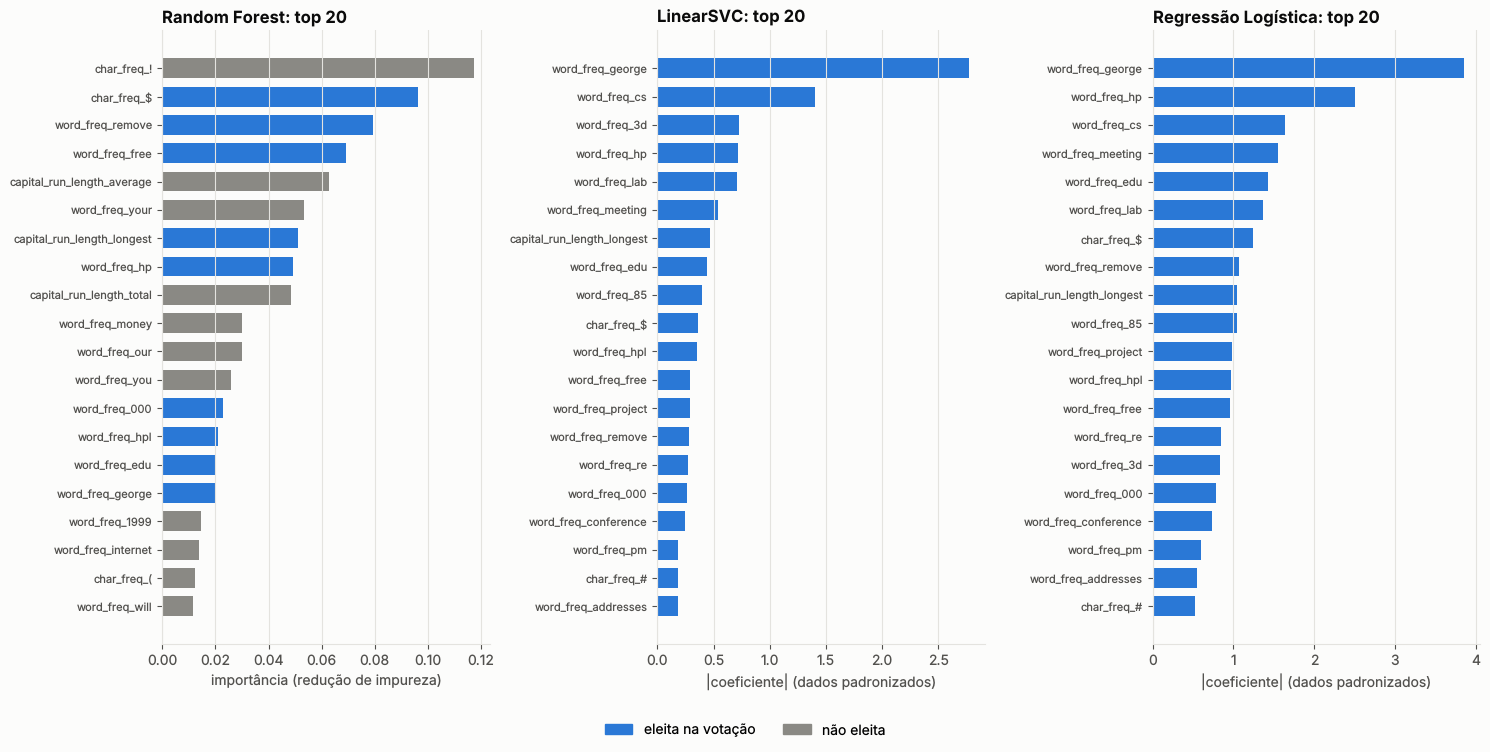

In [5]:
fig = graficos.grafico_importancias(tabela_votos, TOP_K)
graficos.salvar_figura(fig, cfg, CYCLE_ID, "02_importancias_top20")

## 5. Tabela de votos e regra de eleição

Regra aplicada (parâmetros em `config.yaml`, seção `votacao`):

1. Cada método dá **1 voto** a cada feature do seu top 20 (`top_k`).
2. É eleita a feature com **2 votos ou mais** (`votos_minimos`).
3. **Desempate pela média das posições** nos 3 rankings (menor média = mais importante no conjunto). Ele define a ordem das eleitas e, se for preciso completar o mínimo, decide quem entra entre as que têm o mesmo número de votos.
4. **Mínimo de 10 features** (`minimo_features`): se menos de 10 tiverem 2 votos, a lista é completada com as não eleitas mais bem colocadas pelo critério (votos, média das posições). Isso evita um modelo com features de menos caso os métodos discordem muito.

Na figura, cada célula mostra a posição da feature no ranking do método. Célula azul = está no top 20 = 1 voto.

,feature,voto_rf,voto_svc,voto_lr,votos,posicao_rf,posicao_svc,posicao_lr,media_posicoes,eleita,motivo,ordem_final
0,word_freq_hp,1,1,1,3,8,4,2,4.67,True,votos,1.0
1,word_freq_george,1,1,1,3,16,1,1,6.00,True,votos,2.0
2,char_freq_$,1,1,1,3,2,10,7,6.33,True,votos,3.0
3,capital_run_length_longest,1,1,1,3,7,7,9,7.67,True,votos,4.0
4,word_freq_remove,1,1,1,3,3,14,8,8.33,True,votos,5.0
5,word_freq_edu,1,1,1,3,15,8,5,9.33,True,votos,6.0
6,word_freq_free,1,1,1,3,4,12,13,9.67,True,votos,7.0
7,word_freq_hpl,1,1,1,3,14,11,12,12.33,True,votos,8.0
8,word_freq_000,1,1,1,3,13,16,16,15.00,True,votos,9.0
9,word_freq_meeting,0,1,1,2,29,6,4,13.00,True,votos,10.0


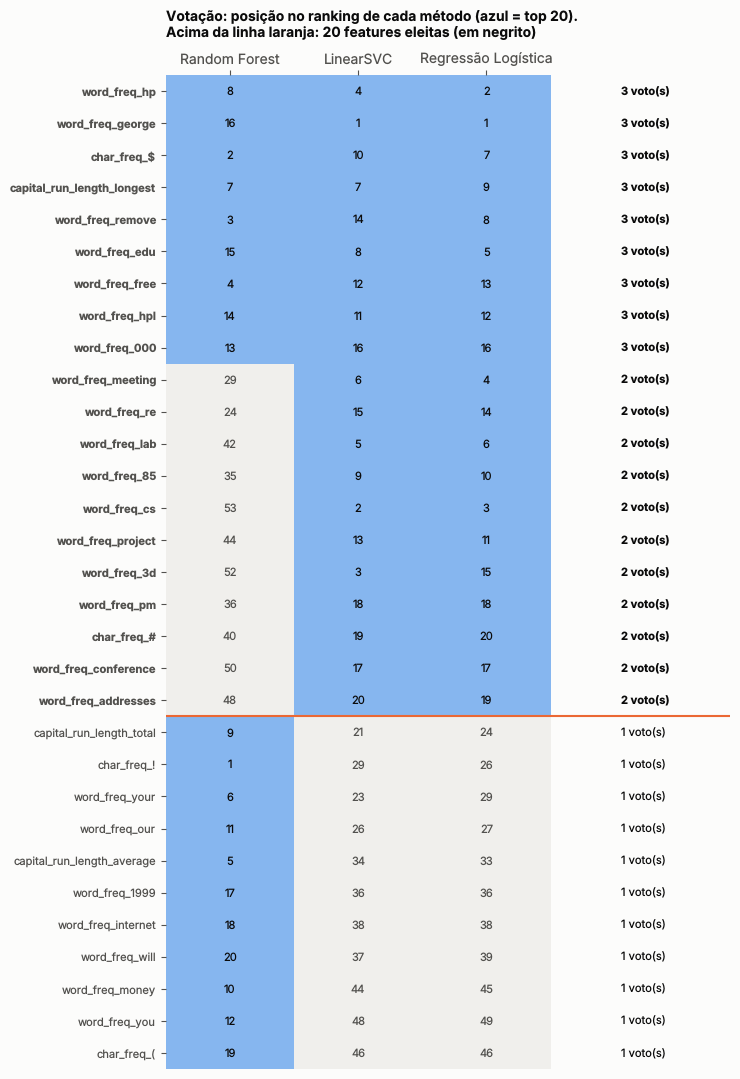

In [6]:
colunas_votos = ["feature", "voto_rf", "voto_svc", "voto_lr", "votos", "posicao_rf", "posicao_svc", "posicao_lr",
                 "media_posicoes", "eleita", "motivo", "ordem_final"]
graficos.salvar_tabela(tabela_votos[colunas_votos], cfg, CYCLE_ID, "02_tabela_votos")
fig = graficos.grafico_votos(tabela_votos, TOP_K)
graficos.salvar_figura(fig, cfg, CYCLE_ID, "02_votos")
tabela_votos[colunas_votos].head(30)

## 6. Features eleitas

Resumo da apuração: quantas features receberam 3, 2, 1 ou 0 votos, se a regra do mínimo precisou ser acionada e a lista final, na ordem do desempate.

In [7]:
distribuicao = tabela_votos["votos"].value_counts().reindex([3, 2, 1, 0], fill_value=0)
completadas = tabela_votos.loc[tabela_votos["motivo"] == "completar_minimo", "feature"].tolist()
print("Features por número de votos:", distribuicao.to_dict())
print(f"Eleitas por voto (>= {VOTOS_MIN}): {int((tabela_votos['votos'] >= VOTOS_MIN).sum())}")
print(f"Regra do mínimo ({MIN_FEATURES}) acionada: {'sim, completadas: ' + str(completadas) if completadas else 'não'}")
print(f"Total de features eleitas: {len(ELEITAS)}")
eleitas_df = tabela_votos[tabela_votos["eleita"]].sort_values("ordem_final")[["ordem_final", "feature", "votos", "media_posicoes", "motivo"]]
graficos.salvar_tabela(eleitas_df, cfg, CYCLE_ID, "02_features_eleitas")
eleitas_df

Features por número de votos: {3: 9, 2: 11, 1: 11, 0: 26}
Eleitas por voto (>= 2): 20
Regra do mínimo (10) acionada: não
Total de features eleitas: 20


,ordem_final,feature,votos,media_posicoes,motivo
0,1.0,word_freq_hp,3,4.67,votos
1,2.0,word_freq_george,3,6.00,votos
2,3.0,char_freq_$,3,6.33,votos
3,4.0,capital_run_length_longest,3,7.67,votos
4,5.0,word_freq_remove,3,8.33,votos
5,6.0,word_freq_edu,3,9.33,votos
6,7.0,word_freq_free,3,9.67,votos
7,8.0,word_freq_hpl,3,12.33,votos
8,9.0,word_freq_000,3,15.00,votos
9,10.0,word_freq_meeting,2,13.00,votos


## 7. Estabilidade da votação nos folds

Este é o mesmo procedimento que o notebook 03 executa dentro da validação cruzada: para cada um dos 5 folds (os **mesmos** folds, por causa da seed 42), a votação é refeita só com o treino do fold.

* Se uma feature eleita no treino completo também é eleita em 5 de 5 folds, a escolha dela é robusta.
* Features que aparecem em poucos folds estão perto do limite de corte e podem entrar ou sair de um ciclo para outro.

Isso dá uma medida honesta de quanto a seleção depende da amostra, sem usar o teste.

16 de 20 features eleitas aparecem em todos os 5 folds
Tamanho da lista em cada fold: [19, 19, 20, 20, 20]


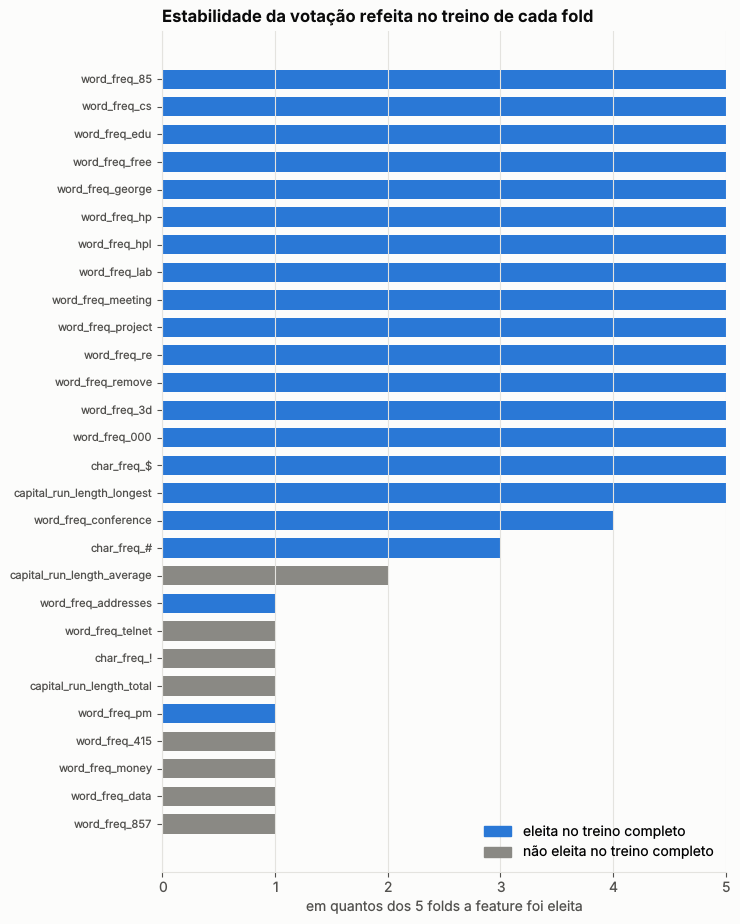

In [8]:
seletores_fold = F.votar_por_fold(cfg, X, y)
N_FOLDS = cfg["validacao"]["n_splits"]
estabilidade = F.estabilidade_votacao(seletores_fold, ELEITAS)
graficos.salvar_tabela(estabilidade, cfg, CYCLE_ID, "02_estabilidade_folds")
fig = graficos.grafico_estabilidade(estabilidade, N_FOLDS)
graficos.salvar_figura(fig, cfg, CYCLE_ID, "02_estabilidade_folds")

estaveis = estabilidade[(estabilidade["folds_eleita"] == N_FOLDS) & estabilidade["eleita_no_treino_completo"]]
print(f"{len(estaveis)} de {len(ELEITAS)} features eleitas aparecem em todos os {N_FOLDS} folds")
print("Tamanho da lista em cada fold:", [len(s.features_eleitas_) for s in seletores_fold])

## 8. Gravação de `artifacts/features_eleitas.json`

O arquivo guarda a lista final, a regra usada e os identificadores do ciclo. O notebook 03 confere que o `SeletorPorVotacao`, ajustado no treino completo dentro do Pipeline de cada modelo, chega exatamente nesta mesma lista.

In [9]:
resultado = {
    "cycle_id": CYCLE_ID,
    "data_version": DATA_VERSION,
    "gerado_em": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "features_eleitas": ELEITAS,
    "n_features_eleitas": len(ELEITAS),
    "regra": {"top_k": TOP_K, "votos_minimos": VOTOS_MIN, "minimo_features": MIN_FEATURES,
              "desempate": v["desempate"], "metodos": list(v["modelos"])},
    "completadas_pelo_minimo": completadas,
    "distribuicao_votos": {str(k): int(n) for k, n in distribuicao.items()},
}
salvar_json(resultado, cfg["caminhos"]["features_eleitas"])
print(json.dumps(resultado, indent=2, ensure_ascii=False))

{
  "cycle_id": "20261122T202358Z",
  "data_version": "lotes-01+02_h0ce6906487cc",
  "gerado_em": "2026-11-22T20:24:12+00:00",
  "features_eleitas": [
    "word_freq_hp",
    "word_freq_george",
    "char_freq_$",
    "capital_run_length_longest",
    "word_freq_remove",
    "word_freq_edu",
    "word_freq_free",
    "word_freq_hpl",
    "word_freq_000",
    "word_freq_meeting",
    "word_freq_re",
    "word_freq_lab",
    "word_freq_85",
    "word_freq_cs",
    "word_freq_project",
    "word_freq_3d",
    "word_freq_pm",
    "char_freq_#",
    "word_freq_conference",
    "word_freq_addresses"
  ],
  "n_features_eleitas": 20,
  "regra": {
    "top_k": 20,
    "votos_minimos": 2,
    "minimo_features": 10,
    "desempate": "media_posicoes",
    "metodos": [
      "RandomForestClassifier",
      "LinearSVC",
      "LogisticRegression"
    ]
  },
  "completadas_pelo_minimo": [],
  "distribuicao_votos": {
    "3": 9,
    "2": 11,
    "1": 11,
    "0": 26
  }
}


## 9. Registro no MLflow

Um run de **votação** por ciclo, no experimento definido em `config.yaml`. Ele guarda:

* **parâmetros:** regra de votação, hiperparâmetros dos três métodos, seed, `cycle_id` e `data_version`;
* **métricas:** número de features eleitas e distribuição dos votos;
* **artefatos:** rankings, tabela de votos, lista de eleitas, estabilidade e os gráficos.

As tags `etapa`, `cycle_id` e `data_version` permitem filtrar na interface do MLflow todos os runs de um mesmo ciclo.

In [10]:
configurar_mlflow(cfg)
pasta_fig = caminho(cfg["caminhos"]["figuras"])

with mlflow.start_run(run_name=f"votacao_{CYCLE_ID}") as run:
    mlflow.set_tags({"etapa": "votacao", "cycle_id": CYCLE_ID, "data_version": DATA_VERSION})
    mlflow.log_params({"cycle_id": CYCLE_ID, "data_version": DATA_VERSION, "seed": SEED,
                       "top_k": TOP_K, "votos_minimos": VOTOS_MIN, "minimo_features": MIN_FEATURES,
                       "desempate": v["desempate"], "n_linhas_treino": len(X)})
    for metodo, params in v["modelos"].items():
        mlflow.log_params({f"{F.SIGLAS[metodo]}__{k}": val for k, val in (params or {}).items()})
    mlflow.log_metrics({"n_features_eleitas": len(ELEITAS),
                        **{f"n_features_{k}_votos": int(n) for k, n in distribuicao.items()},
                        "n_eleitas_estaveis_todos_folds": len(estaveis)})
    mlflow.log_dict(resultado, "features_eleitas.json")
    for arq in sorted(pasta_fig.glob(f"{CYCLE_ID}_02_*")):
        mlflow.log_artifact(str(arq), artifact_path="votacao")
    RUN_ID_VOTACAO = run.info.run_id

ingestao.atualizar_ciclo(cfg, etapas={**ciclo["etapas"], "02_votacao": "concluido"},
                         run_id_votacao=RUN_ID_VOTACAO, features_eleitas=ELEITAS)
print("Run de votação registrado:", RUN_ID_VOTACAO)

Run de votação registrado: b1a643937b3249acbfcc8e96e54485dd


## 10. Resumo

| Arquivo em `reports/figuras/` | Conteúdo |
|---|---|
| `<cycle_id>_02_rankings_completos.csv` e `_02_ranking_<rf/svc/lr>.csv` | ranking das 57 features em cada método |
| `<cycle_id>_02_importancias_top20.png` | top 20 de cada método |
| `<cycle_id>_02_tabela_votos.csv` e `_02_votos.png` | votos por feature e método |
| `<cycle_id>_02_features_eleitas.csv` | lista final, na ordem do desempate |
| `<cycle_id>_02_estabilidade_folds.csv` / `.png` | quantas vezes cada feature foi eleita nos folds |

Próximo passo: **notebook 03**, competição entre os modelos A e B e decisão de promoção.

In [11]:
print(f"Ciclo {CYCLE_ID}: {len(ELEITAS)} features eleitas -> {ELEITAS}")

Ciclo 20261122T202358Z: 20 features eleitas -> ['word_freq_hp', 'word_freq_george', 'char_freq_$', 'capital_run_length_longest', 'word_freq_remove', 'word_freq_edu', 'word_freq_free', 'word_freq_hpl', 'word_freq_000', 'word_freq_meeting', 'word_freq_re', 'word_freq_lab', 'word_freq_85', 'word_freq_cs', 'word_freq_project', 'word_freq_3d', 'word_freq_pm', 'char_freq_#', 'word_freq_conference', 'word_freq_addresses']
